In [1]:
%pip install pandas numpy matplotlib seaborn plotly scipy scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from pathlib import Path

DATA_PATH = Path(r"C:\Users\tanuj\Downloads\ecommerce_data")

customers = pd.read_csv(DATA_PATH / "customers.csv")
products = pd.read_csv(DATA_PATH / "products.csv")
sales = pd.read_csv(DATA_PATH / "sales.csv")

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Sales:", sales.shape)

Customers: (40000, 15)
Products: (2000, 12)
Sales: (250000, 21)


In [6]:
display(customers.head())

,Customer_ID,Customer_Name,Gender,Age,Age_Group,Date_of_Birth,Email,Phone,City,State,Pincode,Registration_Date,Customer_Tier,Total_Orders,Total_Spent
0,CUST00000001,Akash Agarwal,male,48,46-55,1977-01-13,akashagarwal@gmail.com,+91-9625152011,Patiala,Punjab,122521,2024-01-28,Gold,5,"40,098.48"
1,CUST00000002,Farhan Rahman,male,73,65+,1952-01-20,farhanrahman@gmail.com,+91-8593009465,Durgapur,West Bengal,226518,2023-08-25,Platinum,8,"63,676.24"
2,CUST00000003,Suresh Kumar,male,31,26-35,1994-01-09,sureshkumar755@gmail.com,+91-7935884774,Gurugram,Haryana,520400,2023-08-30,Silver,0,0.00
3,CUST00000004,Aditya Pandey,male,41,36-45,1984-01-12,adityapandey@outlook.com,+91-9015046072,Kolkata,West Bengal,735356,2024-03-11,Platinum,5,"288,324.84"
4,CUST00000005,Hina Khan,female,53,46-55,1972-01-15,hinakhan433@gmail.com,+91-8813094271,Noida,UP,985141,2024-04-19,Platinum,4,"69,265.75"


In [7]:
display(products.head())

,Product_ID,Product_Name,Category,Brand,Original_Price,Discount_Percent,Discount_Amount,Selling_Price,Stock_Quantity,Weight_kg,Avg_Rating,Total_Reviews
0,PROD000001,Samsung Mobile V5,Electronics,Samsung,"130,561.34",23,"30,029.11","100,532.23",159,2.63,4.49,102
1,PROD000002,HP Laptop V5,Electronics,HP,"36,494.92",34,"12,408.27","24,086.65",54,4.19,4.32,107
2,PROD000003,boAt Headphones V2,Electronics,boAt,"106,587.94",42,"44,766.93","61,821.01",638,1.48,4.31,99
3,PROD000004,Noise Watch V7,Electronics,Noise,"81,275.27",47,"38,199.38","43,075.89",572,3.30,4.42,127
4,PROD000005,Apple iPhone V4,Electronics,Apple,"13,099.36",43,"5,632.72","7,466.64",865,3.71,4.37,98


In [8]:
display(sales.head())

,Order_ID,Customer_ID,Product_ID,Order_Date,Order_Time,Delivery_Date,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Code,Coupon_Discount,Total_Amount,Payment_Mode,Order_Status,Rating,Review_Text,City,State,Customer_Age,Customer_Age_Group
0,ORD0000000001,CUST00014303,PROD001017,2026-06-07,08:20:00,2026-06-10,1,"2,622.46","2,622.46",0.00,NaN,0.00,"2,622.46",COD,Delivered,NaN,NaN,Chennai,Tamil Nadu,43,36-45
1,ORD0000000002,CUST00034253,PROD000703,2025-02-04,20:05:00,2025-02-07,1,"90,258.00","90,258.00",0.00,NaN,0.00,"90,258.00",COD,Delivered,4.00,Nice quality,Durgapur,West Bengal,22,18-25
2,ORD0000000003,CUST00000421,PROD000318,2026-03-12,14:59:00,2026-03-19,1,"3,536.50","3,536.50",0.00,NaN,0.00,"3,536.50",UPI,Processing,NaN,NaN,Patiala,Punjab,41,36-45
3,ORD0000000004,CUST00026507,PROD000213,2025-01-27,14:33:00,2025-02-02,1,"34,081.56","34,081.56",0.00,FLAT50,50.00,"34,031.56",Credit Card,Delivered,NaN,NaN,Rajkot,Gujarat,29,26-35
4,ORD0000000005,CUST00009418,PROD001437,2024-06-30,07:19:00,2024-07-02,2,"69,021.17","138,042.34",0.00,NaN,0.00,"138,042.34",UPI,Delivered,NaN,NaN,Surat,Gujarat,39,36-45


Check The DataType 

In [9]:
print("CUSTOMERS")
customers.info()



print("\nPRODUCTS")
products.info()



print("\nSALES")
sales.info()

CUSTOMERS
<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Customer_ID        40000 non-null  str    
 1   Customer_Name      40000 non-null  str    
 2   Gender             40000 non-null  str    
 3   Age                40000 non-null  int64  
 4   Age_Group          40000 non-null  str    
 5   Date_of_Birth      40000 non-null  str    
 6   Email              40000 non-null  str    
 7   Phone              40000 non-null  str    
 8   City               40000 non-null  str    
 9   State              40000 non-null  str    
 10  Pincode            40000 non-null  int64  
 11  Registration_Date  40000 non-null  str    
 12  Customer_Tier      40000 non-null  str    
 13  Total_Orders       40000 non-null  int64  
 14  Total_Spent        40000 non-null  float64
dtypes: float64(1), int64(3), str(11)
memory usage: 8.8 MB

PRODUCTS
<class 

In [12]:
display(customers.describe(include="all").T)


display(products.describe(include="all").T)


display(sales.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer_ID,40000,40000,CUST00000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,40000,927,Swati Patel,82,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,40000,2,male,20003,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"40,000.00",NaN,NaN,NaN,35.31,12.58,18.00,26.00,33.00,43.00,75.00
Age_Group,40000,6,26-35,14059,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date_of_Birth,40000,58,1996-01-09,1466,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Email,40000,26567,meghakumar@gmail.com,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Phone,40000,40000,+91-9625152011,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,40000,39,New Delhi,1105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,40000,10,UP,5218,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_ID,2000,2000,PROD000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Name,2000,350,Philips Mixer V9,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,2000,7,Electronics,290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,2000,33,Nike,114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Original_Price,"2,000.00",NaN,NaN,NaN,"18,323.62","29,472.16",52.25,"1,522.50","4,775.35","22,358.11","149,658.64"
Discount_Percent,"2,000.00",NaN,NaN,NaN,27.47,13.31,5.00,16.00,27.00,39.00,50.00
Discount_Amount,"2,000.00",NaN,NaN,NaN,"5,143.28","9,732.99",6.29,332.26,"1,154.91","5,452.94","71,289.60"
Selling_Price,"2,000.00",NaN,NaN,NaN,"13,180.34","21,514.95",26.13,"1,088.04","3,543.41","16,063.81","136,973.33"
Stock_Quantity,"2,000.00",NaN,NaN,NaN,503.48,287.14,10.00,250.75,504.50,749.00,"1,000.00"
Weight_kg,"2,000.00",NaN,NaN,NaN,2.64,1.37,0.21,1.43,2.73,3.79,5.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,250000,250000,ORD0000000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,250000,39914,CUST00005290,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_ID,250000,2000,PROD000004,267,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,250000,760,2024-07-04,389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Time,250000,1440,11:27:00,219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_Date,250000,765,2025-10-06,393,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"250,000.00",NaN,NaN,NaN,1.25,0.54,1.00,1.00,1.00,1.00,3.00
Unit_Price,"250,000.00",NaN,NaN,NaN,"19,202.48","26,720.50",26.13,"1,551.55","7,208.93","24,433.27","136,973.33"
Order_Value,"250,000.00",NaN,NaN,NaN,"23,967.86","37,629.32",26.13,"1,825.89","8,411.16","28,612.81","410,919.99"
Shipping_Cost,"250,000.00",NaN,NaN,NaN,4.91,18.14,0.00,0.00,0.00,0.00,90.00


Check Missing Values

In [13]:
def missing_value_report(df):
    report = pd.DataFrame({
        "Missing_Count": df.isna().sum(),
        "Missing_Percentage": df.isna().mean() * 100
    })
    return report[report["Missing_Count"] > 0].sort_values(
        "Missing_Percentage", ascending=False
    )

print("CUSTOMERS")
display(missing_value_report(customers))

print("PRODUCTS")
display(missing_value_report(products))

print("SALES")
display(missing_value_report(sales))

CUSTOMERS


,Missing_Count,Missing_Percentage


PRODUCTS


,Missing_Count,Missing_Percentage


SALES


,Missing_Count,Missing_Percentage
Coupon_Code,199815,79.93
Rating,129970,51.99
Review_Text,129970,51.99


In [14]:
print("Customers dataset:", customers.shape)
print("Products dataset:", products.shape)
print("Sales dataset:", sales.shape)

Customers dataset: (40000, 15)
Products dataset: (2000, 12)
Sales dataset: (250000, 21)


In [15]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 21 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Order_ID            250000 non-null  str    
 1   Customer_ID         250000 non-null  str    
 2   Product_ID          250000 non-null  str    
 3   Order_Date          250000 non-null  str    
 4   Order_Time          250000 non-null  str    
 5   Delivery_Date       250000 non-null  str    
 6   Quantity            250000 non-null  int64  
 7   Unit_Price          250000 non-null  float64
 8   Order_Value         250000 non-null  float64
 9   Shipping_Cost       250000 non-null  float64
 10  Coupon_Code         50185 non-null   str    
 11  Coupon_Discount     250000 non-null  float64
 12  Total_Amount        250000 non-null  float64
 13  Payment_Mode        250000 non-null  str    
 14  Order_Status        250000 non-null  str    
 15  Rating              120030 non-null  float64


In [20]:
sales.describe()
customers.describe()
products.describe()

,Original_Price,Discount_Percent,Discount_Amount,Selling_Price,Stock_Quantity,Weight_kg,Avg_Rating,Total_Reviews
count,"2,000.00","2,000.00","2,000.00","2,000.00","2,000.00","2,000.00","2,000.00","2,000.00"
mean,"18,323.62",27.47,"5,143.28","13,180.34",503.48,2.64,4.40,60.02
std,"29,472.16",13.31,"9,732.99","21,514.95",287.14,1.37,0.10,27.65
min,52.25,5.00,6.29,26.13,10.00,0.21,3.91,15.00
25%,"1,522.50",16.00,332.26,"1,088.04",250.75,1.43,4.34,38.00
50%,"4,775.35",27.00,"1,154.91","3,543.41",504.50,2.73,4.40,54.00
75%,"22,358.11",39.00,"5,452.94","16,063.81",749.00,3.79,4.46,78.00
max,"149,658.64",50.00,"71,289.60","136,973.33","1,000.00",5.00,4.76,139.00


In [24]:
sales.isnull().sum()
customers.isnull().sum()
products.isnull().sum()

Product_ID          0
Product_Name        0
Category            0
Brand               0
Original_Price      0
Discount_Percent    0
Discount_Amount     0
Selling_Price       0
Stock_Quantity      0
Weight_kg           0
Avg_Rating          0
Total_Reviews       0
dtype: int64

In [25]:
sales.duplicated().sum()
customers.duplicated().sum()
products.duplicated().sum()

np.int64(0)

In [26]:
# 1. How many unique customers are in the sales data?
print(sales["Customer_ID"].nunique())

# 2. Which order statuses exist?
print(sales["Order_Status"].unique())

# 3. How many orders are in each status?
print(sales["Order_Status"].value_counts())

# 4. What is the average order value?
print(sales["Order_Value"].mean())

# 5. Show the 10 highest order values
display(sales.nlargest(10, "Order_Value"))

39914
<ArrowStringArray>
['Delivered', 'Processing', 'Returned', 'Cancelled', 'Shipped']
Length: 5, dtype: str
Order_Status
Delivered     200139
Cancelled      12507
Returned       12493
Shipped        12459
Processing     12402
Name: count, dtype: int64
23967.86219204


,Order_ID,Customer_ID,Product_ID,Order_Date,Order_Time,Delivery_Date,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Code,Coupon_Discount,Total_Amount,Payment_Mode,Order_Status,Rating,Review_Text,City,State,Customer_Age,Customer_Age_Group
14964,ORD0000014965,CUST00005239,PROD000250,2024-09-05,12:58:00,2024-09-10,3,"136,973.33","410,919.99",0.00,NaN,0.00,"410,919.99",COD,Delivered,NaN,NaN,Durgapur,West Bengal,18,18-25
26329,ORD0000026330,CUST00004117,PROD000250,2024-07-28,01:55:00,2024-08-01,3,"136,973.33","410,919.99",0.00,SAVE10,"41,092.00","369,827.99",UPI,Processing,NaN,NaN,Ludhiana,Punjab,44,36-45
57434,ORD0000057435,CUST00024340,PROD000250,2024-07-04,13:43:00,2024-07-08,3,"136,973.33","410,919.99",0.00,NaN,0.00,"410,919.99",COD,Delivered,5.00,Highly recommended!,Dwarka,Delhi,34,26-35
129835,ORD0000129836,CUST00013240,PROD000250,2025-10-03,16:38:00,2025-10-07,3,"136,973.33","410,919.99",0.00,FLAT50,50.00,"410,869.99",UPI,Cancelled,NaN,NaN,Nagpur,Maharashtra,26,26-35
133400,ORD0000133401,CUST00009492,PROD000250,2024-12-24,14:50:00,2024-12-30,3,"136,973.33","410,919.99",0.00,SAVE10,"41,092.00","369,827.99",Credit Card,Cancelled,NaN,NaN,Udaipur,Rajasthan,20,18-25
149857,ORD0000149858,CUST00010421,PROD000250,2024-12-07,09:15:00,2024-12-13,3,"136,973.33","410,919.99",0.00,NaN,0.00,"410,919.99",COD,Delivered,4.00,Good product,Chennai,Tamil Nadu,29,26-35
162132,ORD0000162133,CUST00008047,PROD000250,2025-10-29,09:09:00,2025-11-02,3,"136,973.33","410,919.99",0.00,NaN,0.00,"410,919.99",UPI,Shipped,NaN,NaN,Kanpur,UP,33,26-35
170534,ORD0000170535,CUST00020553,PROD000250,2026-05-22,18:18:00,2026-05-29,3,"136,973.33","410,919.99",0.00,NaN,0.00,"410,919.99",COD,Returned,NaN,NaN,Nagpur,Maharashtra,32,26-35
227890,ORD0000227891,CUST00026703,PROD000250,2025-06-27,10:12:00,2025-06-29,3,"136,973.33","410,919.99",0.00,NaN,0.00,"410,919.99",Credit Card,Returned,NaN,NaN,Nagpur,Maharashtra,19,18-25
230609,ORD0000230610,CUST00013806,PROD000250,2025-08-22,13:51:00,2025-08-28,3,"136,973.33","410,919.99",0.00,DIWALI100,100.00,"410,819.99",UPI,Delivered,4.00,Value for money,Madurai,Tamil Nadu,22,18-25


In [28]:
sales["Order_Date"] = pd.to_datetime(
    sales["Order_Date"], errors="coerce"
)

sales["Delivery_Date"] = pd.to_datetime(
    sales["Delivery_Date"], errors="coerce"
)

customers["Date_of_Birth"] = pd.to_datetime(
    customers["Date_of_Birth"], errors="coerce"
)

customers["Registration_Date"] = pd.to_datetime(
    customers["Registration_Date"], errors="coerce"
)

In [29]:
print(sales[["Order_Date", "Delivery_Date"]].dtypes)
print(customers[["Date_of_Birth", "Registration_Date"]].dtypes)

Order_Date       datetime64[us]
Delivery_Date    datetime64[us]
dtype: object
Date_of_Birth        datetime64[us]
Registration_Date    datetime64[us]
dtype: object


In [30]:
numeric_columns = [
    "Quantity",
    "Unit_Price",
    "Order_Value",
    "Shipping_Cost",
    "Coupon_Discount",
    "Total_Amount"
]

for col in numeric_columns:
    print(f"{col}: {(sales[col] < 0).sum()} negative values")

Quantity: 0 negative values
Unit_Price: 0 negative values
Order_Value: 0 negative values
Shipping_Cost: 0 negative values
Coupon_Discount: 0 negative values
Total_Amount: 5 negative values


In [31]:
print(sales["Order_Status"].value_counts(dropna=False))
print(sales["Payment_Mode"].value_counts(dropna=False))

Order_Status
Delivered     200139
Cancelled      12507
Returned       12493
Shipped        12459
Processing     12402
Name: count, dtype: int64
Payment_Mode
UPI            128474
COD             82093
Debit Card      28856
Credit Card     10577
Name: count, dtype: int64


In [32]:
text_columns = sales.select_dtypes(include="object").columns

for col in text_columns:
    sales[col] = sales[col].str.strip()

In [33]:
print("Sales shape:", sales.shape)
print("Missing values:", sales.isnull().sum().sum())
print("Duplicate rows:", sales.duplicated().sum())

display(sales.head())

Sales shape: (250000, 21)
Missing values: 459755
Duplicate rows: 0


,Order_ID,Customer_ID,Product_ID,Order_Date,Order_Time,Delivery_Date,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Code,Coupon_Discount,Total_Amount,Payment_Mode,Order_Status,Rating,Review_Text,City,State,Customer_Age,Customer_Age_Group
0,ORD0000000001,CUST00014303,PROD001017,2026-06-07,08:20:00,2026-06-10,1,"2,622.46","2,622.46",0.00,NaN,0.00,"2,622.46",COD,Delivered,NaN,NaN,Chennai,Tamil Nadu,43,36-45
1,ORD0000000002,CUST00034253,PROD000703,2025-02-04,20:05:00,2025-02-07,1,"90,258.00","90,258.00",0.00,NaN,0.00,"90,258.00",COD,Delivered,4.00,Nice quality,Durgapur,West Bengal,22,18-25
2,ORD0000000003,CUST00000421,PROD000318,2026-03-12,14:59:00,2026-03-19,1,"3,536.50","3,536.50",0.00,NaN,0.00,"3,536.50",UPI,Processing,NaN,NaN,Patiala,Punjab,41,36-45
3,ORD0000000004,CUST00026507,PROD000213,2025-01-27,14:33:00,2025-02-02,1,"34,081.56","34,081.56",0.00,FLAT50,50.00,"34,031.56",Credit Card,Delivered,NaN,NaN,Rajkot,Gujarat,29,26-35
4,ORD0000000005,CUST00009418,PROD001437,2024-06-30,07:19:00,2024-07-02,2,"69,021.17","138,042.34",0.00,NaN,0.00,"138,042.34",UPI,Delivered,NaN,NaN,Surat,Gujarat,39,36-45


In [35]:
customers_clean = customers.copy()
products_clean = products.copy()
sales_clean = sales.copy()

Exploratory Data Analysis (EDA)

In [36]:
sales.describe()

,Order_Date,Delivery_Date,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Discount,Total_Amount,Rating,Customer_Age
count,250000,250000,"250,000.00","250,000.00","250,000.00","250,000.00","250,000.00","250,000.00","120,030.00","250,000.00"
mean,2025-06-15 09:37:10.156799,2025-06-19 21:38:16.512000,1.25,"19,202.48","23,967.86",4.91,250.00,"23,722.77",4.40,35.31
min,2024-06-01 00:00:00,2024-06-03 00:00:00,1.00,26.13,26.13,0.00,0.00,-21.56,3.00,18.00
25%,2024-12-08 00:00:00,2024-12-13 00:00:00,1.00,"1,551.55","1,825.89",0.00,0.00,"1,803.90",4.00,26.00
50%,2025-06-15 00:00:00,2025-06-19 00:00:00,1.00,"7,208.93","8,411.16",0.00,0.00,"8,339.49",4.00,33.00
75%,2025-12-22 00:00:00,2025-12-27 00:00:00,1.00,"24,433.27","28,612.81",0.00,0.00,"28,344.92",5.00,43.00
max,2026-06-30 00:00:00,2026-07-07 00:00:00,3.00,"136,973.33","410,919.99",90.00,"41,092.00","410,919.99",5.00,75.00
std,NaN,NaN,0.54,"26,720.50","37,629.32",18.14,"1,399.93","37,267.64",0.66,12.57


In [37]:
print("Average Order Value:", sales["Order_Value"].mean())
print("Median Order Value:", sales["Order_Value"].median())
print("Maximum Order Value:", sales["Order_Value"].max())
print("Minimum Order Value:", sales["Order_Value"].min())
print("Total Quantity Sold:", sales["Quantity"].sum())

Average Order Value: 23967.86219204
Median Order Value: 8411.16
Maximum Order Value: 410919.99
Minimum Order Value: 26.13
Total Quantity Sold: 312395


In [38]:
sales["Order_Status"].value_counts()

Order_Status
Delivered     200139
Cancelled      12507
Returned       12493
Shipped        12459
Processing     12402
Name: count, dtype: int64

In [39]:
status_percentage = (
    sales["Order_Status"].value_counts(normalize=True) * 100
).round(2)

print(status_percentage)

Order_Status
Delivered    80.06
Cancelled     5.00
Returned      5.00
Shipped       4.98
Processing    4.96
Name: proportion, dtype: float64


In [40]:
payment_counts = sales["Payment_Mode"].value_counts()

print(payment_counts)

Payment_Mode
UPI            128474
COD             82093
Debit Card      28856
Credit Card     10577
Name: count, dtype: int64


In [41]:
print("Most popular payment method:", payment_counts.idxmax())
print("Number of records:", payment_counts.max())

Most popular payment method: UPI
Number of records: 128474


find top selling products 

In [42]:
print(products.columns.tolist())

['Product_ID', 'Product_Name', 'Category', 'Brand', 'Original_Price', 'Discount_Percent', 'Discount_Amount', 'Selling_Price', 'Stock_Quantity', 'Weight_kg', 'Avg_Rating', 'Total_Reviews']


In [43]:
sales_product = sales.merge(
    products,
    on="Product_ID",
    how="left"
)

sales_product.head()

,Order_ID,Customer_ID,Product_ID,Order_Date,Order_Time,Delivery_Date,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Code,Coupon_Discount,Total_Amount,Payment_Mode,Order_Status,Rating,Review_Text,City,State,Customer_Age,Customer_Age_Group,Product_Name,Category,Brand,Original_Price,Discount_Percent,Discount_Amount,Selling_Price,Stock_Quantity,Weight_kg,Avg_Rating,Total_Reviews
0,ORD0000000001,CUST00014303,PROD001017,2026-06-07,08:20:00,2026-06-10,1,"2,622.46","2,622.46",0.00,NaN,0.00,"2,622.46",COD,Delivered,NaN,NaN,Chennai,Tamil Nadu,43,36-45,HP Laptop V7,Electronics,HP,"3,746.37",30,"1,123.91","2,622.46",290,4.63,4.49,110
1,ORD0000000002,CUST00034253,PROD000703,2025-02-04,20:05:00,2025-02-07,1,"90,258.00","90,258.00",0.00,NaN,0.00,"90,258.00",COD,Delivered,4.00,Nice quality,Durgapur,West Bengal,22,18-25,boAt Headphones V3,Electronics,boAt,"145,577.42",38,"55,319.42","90,258.00",572,3.98,4.38,104
2,ORD0000000003,CUST00000421,PROD000318,2026-03-12,14:59:00,2026-03-19,1,"3,536.50","3,536.50",0.00,NaN,0.00,"3,536.50",UPI,Processing,NaN,NaN,Patiala,Punjab,41,36-45,boAt Headphones V8,Electronics,boAt,"7,073.01",50,"3,536.51","3,536.50",749,3.61,4.32,109
3,ORD0000000004,CUST00026507,PROD000213,2025-01-27,14:33:00,2025-02-02,1,"34,081.56","34,081.56",0.00,FLAT50,50.00,"34,031.56",Credit Card,Delivered,NaN,NaN,Rajkot,Gujarat,29,26-35,boAt Headphones V2,Electronics,boAt,"43,141.21",21,"9,059.65","34,081.56",743,0.70,4.43,116
4,ORD0000000005,CUST00009418,PROD001437,2024-06-30,07:19:00,2024-07-02,2,"69,021.17","138,042.34",0.00,NaN,0.00,"138,042.34",UPI,Delivered,NaN,NaN,Surat,Gujarat,39,36-45,HP Laptop V10,Electronics,HP,"73,426.78",6,"4,405.61","69,021.17",81,1.21,4.30,100


In [44]:
top_products = (
    sales_product.groupby("Product_Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

Product_Name
boAt Headphones V6    3473
Samsung Mobile V4     2820
HP Laptop V10         2813
Samsung Mobile V3     2798
boAt Headphones V8    2688
Noise Watch V7        2629
Apple iPhone V7       2620
HP Laptop V5          2546
Apple iPhone V4       2525
Noise Watch V1        2308
Name: Quantity, dtype: int64

Which product categories have the highest sales amounts?

In [45]:
category_sales = (
    sales_product.groupby("Category")["Total_Amount"]
    .sum()
    .sort_values(ascending=False)
)

display(category_sales)

Category
Electronics   4,306,349,999.63
Home            716,125,082.65
Sports          475,839,145.04
Fashion         333,678,794.01
Grocery          41,771,397.25
Beauty           38,265,800.74
Books            18,663,034.98
Name: Total_Amount, dtype: float64

In [46]:
sales_customer = sales.merge(
    customers,
    on="Customer_ID",
    how="left",
    suffixes=("", "_Customer")
)

sales_customer.head()

,Order_ID,Customer_ID,Product_ID,Order_Date,Order_Time,Delivery_Date,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Code,Coupon_Discount,Total_Amount,Payment_Mode,Order_Status,Rating,Review_Text,City,State,Customer_Age,Customer_Age_Group,Customer_Name,Gender,Age,Age_Group,Date_of_Birth,Email,Phone,City_Customer,State_Customer,Pincode,Registration_Date,Customer_Tier,Total_Orders,Total_Spent
0,ORD0000000001,CUST00014303,PROD001017,2026-06-07,08:20:00,2026-06-10,1,"2,622.46","2,622.46",0.00,NaN,0.00,"2,622.46",COD,Delivered,NaN,NaN,Chennai,Tamil Nadu,43,36-45,Suresh Shah,male,43,36-45,1982-01-12,sureshshah@yahoo.com,+91-8432380922,Chennai,Tamil Nadu,505798,2023-06-29,Platinum,5,"319,715.47"
1,ORD0000000002,CUST00034253,PROD000703,2025-02-04,20:05:00,2025-02-07,1,"90,258.00","90,258.00",0.00,NaN,0.00,"90,258.00",COD,Delivered,4.00,Nice quality,Durgapur,West Bengal,22,18-25,Amit Nair,male,22,18-25,2003-01-07,amitnair121@gmail.com,+91-7498436596,Durgapur,West Bengal,177443,2023-12-03,Platinum,3,"218,963.05"
2,ORD0000000003,CUST00000421,PROD000318,2026-03-12,14:59:00,2026-03-19,1,"3,536.50","3,536.50",0.00,NaN,0.00,"3,536.50",UPI,Processing,NaN,NaN,Patiala,Punjab,41,36-45,Aliya Khan,female,41,36-45,1984-01-12,aliyakhan@yahoo.com,+91-9111697218,Patiala,Punjab,891443,2023-06-14,Platinum,7,"201,868.75"
3,ORD0000000004,CUST00026507,PROD000213,2025-01-27,14:33:00,2025-02-02,1,"34,081.56","34,081.56",0.00,FLAT50,50.00,"34,031.56",Credit Card,Delivered,NaN,NaN,Rajkot,Gujarat,29,26-35,Kavya Gupta,female,29,26-35,1996-01-09,kavyagupta862@yahoo.com,+91-9953635765,Rajkot,Gujarat,537887,2023-06-20,Platinum,8,"473,269.13"
4,ORD0000000005,CUST00009418,PROD001437,2024-06-30,07:19:00,2024-07-02,2,"69,021.17","138,042.34",0.00,NaN,0.00,"138,042.34",UPI,Delivered,NaN,NaN,Surat,Gujarat,39,36-45,Suresh Tiwari,male,39,36-45,1986-01-11,sureshtiwari584@gmail.com,+91-9294706553,Surat,Gujarat,802766,2023-12-17,Platinum,5,"539,781.79"


In [47]:
top_customers = (
    sales_customer.groupby("Customer_ID")["Total_Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_customers)

Customer_ID
CUST00018065   1,071,444.02
CUST00017168     947,342.64
CUST00000699     913,494.32
CUST00023830     898,661.20
CUST00004600     890,131.55
CUST00033067     888,994.45
CUST00020280     877,895.43
CUST00021066     876,932.74
CUST00003487     869,402.68
CUST00009202     843,527.62
Name: Total_Amount, dtype: float64

In [48]:
sales["Order_Date"] = pd.to_datetime(
    sales["Order_Date"], errors="coerce"
)

In [49]:
monthly_sales = (
    sales.dropna(subset=["Order_Date"])
    .groupby(sales["Order_Date"].dt.to_period("M"))["Total_Amount"]
    .sum()
)

display(monthly_sales)

Order_Date
2024-06   240,781,697.45
2024-07   240,966,259.62
2024-08   240,194,624.37
2024-09   229,331,306.00
2024-10   239,971,596.64
2024-11   234,557,799.66
2024-12   241,951,017.68
2025-01   241,229,155.24
2025-02   215,193,135.50
2025-03   242,631,110.34
2025-04   241,486,810.70
2025-05   241,196,492.32
2025-06   232,215,999.79
2025-07   238,134,009.13
2025-08   246,113,995.99
2025-09   228,021,990.76
2025-10   247,499,848.65
2025-11   232,572,145.93
2025-12   243,617,086.27
2026-01   236,928,560.92
2026-02   225,168,645.58
2026-03   248,032,774.34
2026-04   231,727,663.65
2026-05   235,484,942.44
2026-06   235,684,585.33
Freq: M, Name: Total_Amount, dtype: float64

In [50]:
numeric_data = sales.select_dtypes(include="number")

correlation = numeric_data.corr()

display(correlation.round(2))

,Quantity,Unit_Price,Order_Value,Shipping_Cost,Coupon_Discount,Total_Amount,Rating,Customer_Age
Quantity,1.00,-0.00,0.27,-0.08,0.07,0.27,0.00,-0.00
Unit_Price,-0.00,1.00,0.88,-0.19,0.24,0.88,0.00,-0.16
Order_Value,0.27,0.88,1.00,-0.17,0.27,1.00,0.00,-0.14
Shipping_Cost,-0.08,-0.19,-0.17,1.00,-0.05,-0.17,-0.00,0.07
Coupon_Discount,0.07,0.24,0.27,-0.05,1.00,0.24,0.00,-0.04
Total_Amount,0.27,0.88,1.00,-0.17,0.24,1.00,0.00,-0.14
Rating,0.00,0.00,0.00,-0.00,0.00,0.00,1.00,0.00
Customer_Age,-0.00,-0.16,-0.14,0.07,-0.04,-0.14,0.00,1.00


Data visualization
Order status distribution

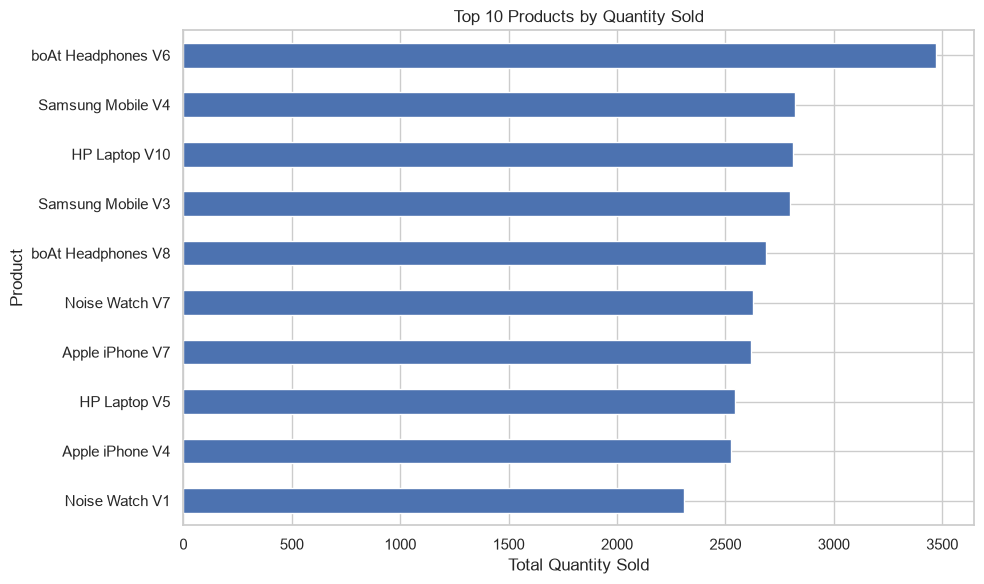

In [56]:
top_products.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

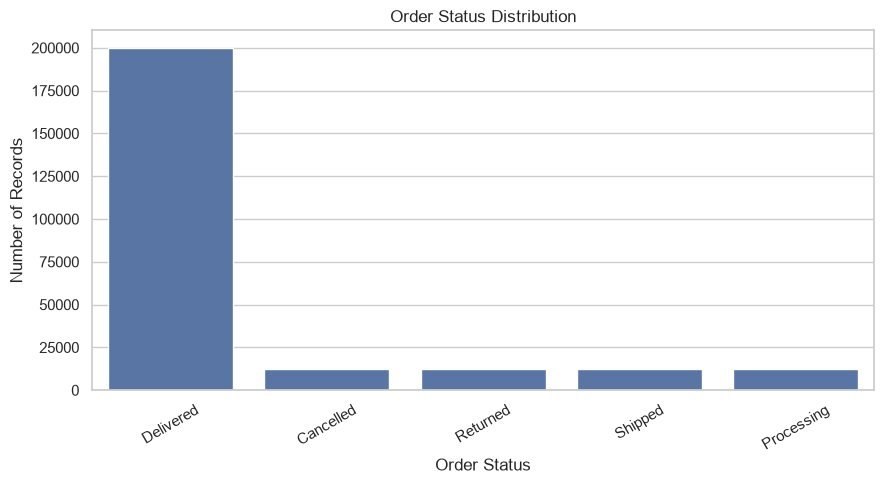

In [57]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=sales,
    x="Order_Status",
    order=sales["Order_Status"].value_counts().index
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Monthly sales trend

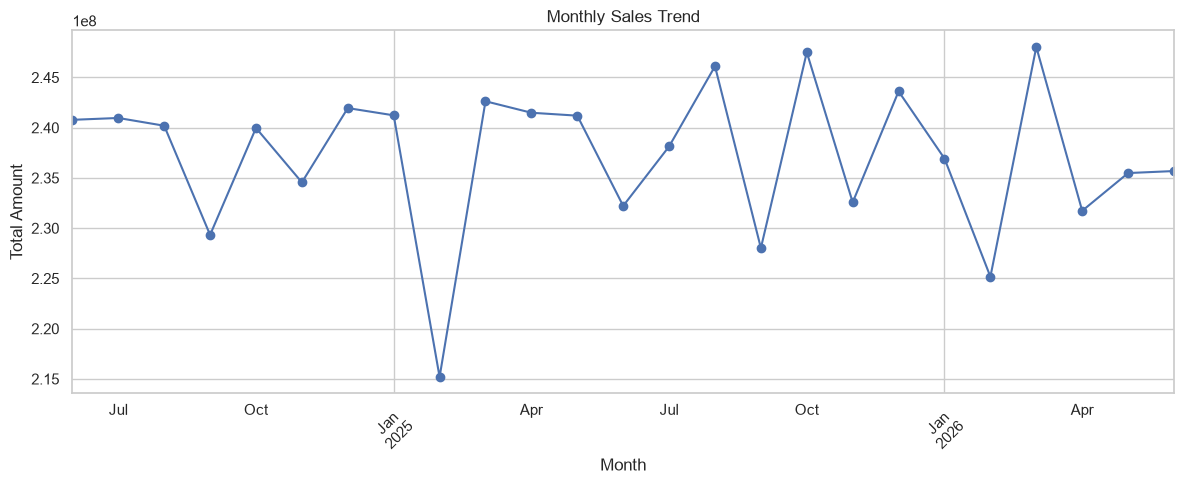

In [58]:
monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correlation heatmap

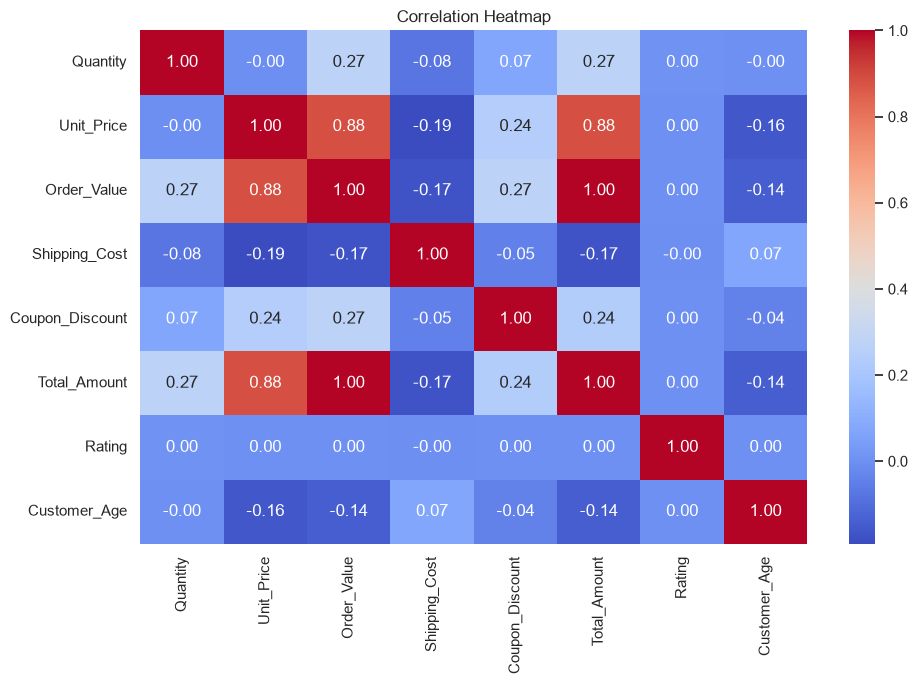

In [59]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Business Insights and Conclusions

1. Which products sell the most?

In [60]:
top_product = top_products.index[0]
top_quantity = top_products.iloc[0]

print("BUSINESS INSIGHT: PRODUCT PERFORMANCE")
print(f"Top-selling product: {top_product}")
print(f"Total quantity sold: {top_quantity}")

print("\nRecommendation:")
print("Maintain sufficient inventory for high-demand products.")

BUSINESS INSIGHT: PRODUCT PERFORMANCE
Top-selling product: boAt Headphones V6
Total quantity sold: 3473

Recommendation:
Maintain sufficient inventory for high-demand products.


.2 Find the best-performing category

In [61]:
best_category = category_sales.idxmax()
best_category_sales = category_sales.max()

print("BUSINESS INSIGHT: CATEGORY PERFORMANCE")
print(f"Top category: {best_category}")
print(f"Recorded total amount: {best_category_sales:,.2f}")

print("\nRecommendation:")
print("Review the leading category's products and customer demand.")

BUSINESS INSIGHT: CATEGORY PERFORMANCE
Top category: Electronics
Recorded total amount: 4,306,349,999.63

Recommendation:
Review the leading category's products and customer demand.


3 Identify the most popular payment method

In [62]:
popular_payment = payment_counts.idxmax()
payment_records = payment_counts.max()

print("BUSINESS INSIGHT: PAYMENT PREFERENCE")
print(f"Most common payment method: {popular_payment}")
print(f"Number of transaction rows: {payment_records:,}")

print("\nRecommendation:")
print("Ensure the most commonly used payment methods remain convenient.")

BUSINESS INSIGHT: PAYMENT PREFERENCE
Most common payment method: UPI
Number of transaction rows: 128,474

Recommendation:
Ensure the most commonly used payment methods remain convenient.


4 Identify the highest-sales month

In [63]:
best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()

print("BUSINESS INSIGHT: MONTHLY SALES")
print(f"Highest-sales month: {best_month}")
print(f"Recorded total amount: {best_month_sales:,.2f}")

print("\nRecommendation:")
print("Investigate demand patterns and plan inventory around peak periods.")

BUSINESS INSIGHT: MONTHLY SALES
Highest-sales month: 2026-03
Recorded total amount: 248,032,774.34

Recommendation:
Investigate demand patterns and plan inventory around peak periods.


5 Review order fulfilment

In [64]:
print("BUSINESS INSIGHT: ORDER STATUS")
display(status_percentage)

print("\nRecommendation:")
print("Investigate cancellation and pending-order patterns.")

BUSINESS INSIGHT: ORDER STATUS


Order_Status
Delivered    80.06
Cancelled     5.00
Returned      5.00
Shipped       4.98
Processing    4.96
Name: proportion, dtype: float64


Recommendation:
Investigate cancellation and pending-order patterns.


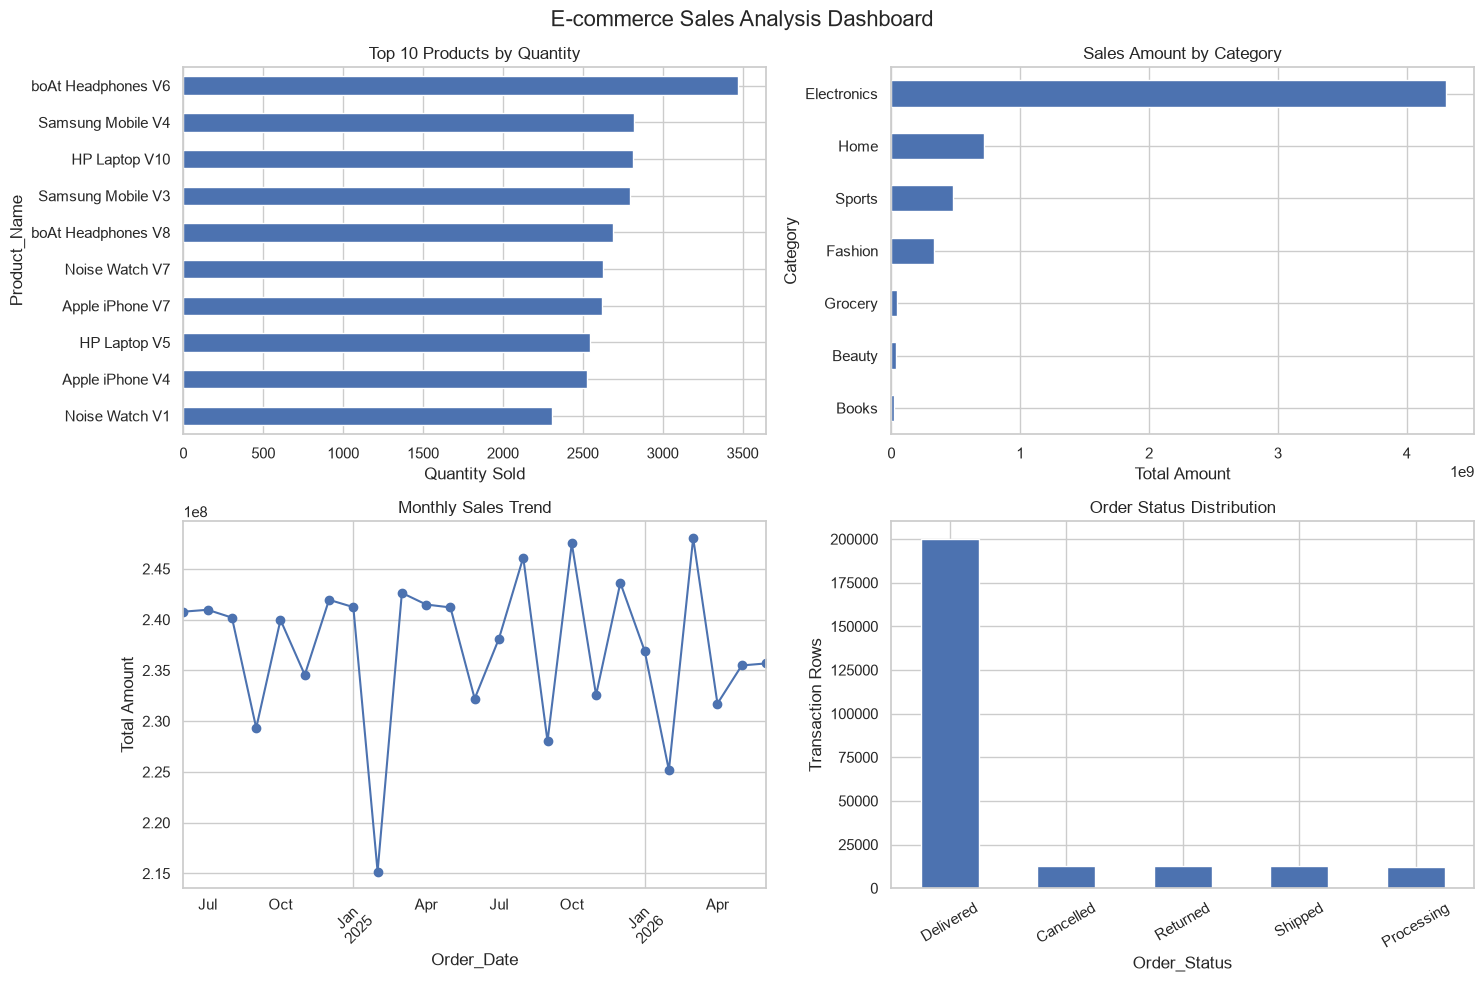

In [65]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Top products
top_products.sort_values().plot(
    kind="barh", ax=axes[0, 0]
)
axes[0, 0].set_title("Top 10 Products by Quantity")
axes[0, 0].set_xlabel("Quantity Sold")

# 2. Category sales
category_sales.sort_values().plot(
    kind="barh", ax=axes[0, 1]
)
axes[0, 1].set_title("Sales Amount by Category")
axes[0, 1].set_xlabel("Total Amount")

# 3. Monthly trend
monthly_sales.plot(
    kind="line", marker="o", ax=axes[1, 0]
)
axes[1, 0].set_title("Monthly Sales Trend")
axes[1, 0].set_ylabel("Total Amount")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Order status
sales["Order_Status"].value_counts().plot(
    kind="bar", ax=axes[1, 1]
)
axes[1, 1].set_title("Order Status Distribution")
axes[1, 1].set_ylabel("Transaction Rows")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.suptitle("E-commerce Sales Analysis Dashboard", fontsize=16)
plt.tight_layout()
plt.show()

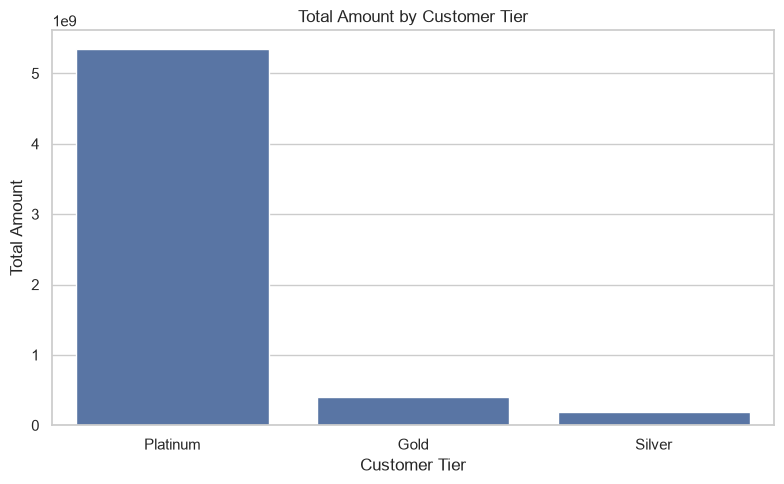

In [66]:
   
tier_sales = (
    sales_customer.groupby("Customer_Tier")["Total_Amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=tier_sales.index, y=tier_sales.values)

plt.title("Total Amount by Customer Tier")
plt.xlabel("Customer Tier")
plt.ylabel("Total Amount")
plt.tight_layout()
plt.show()


Order value by payment method

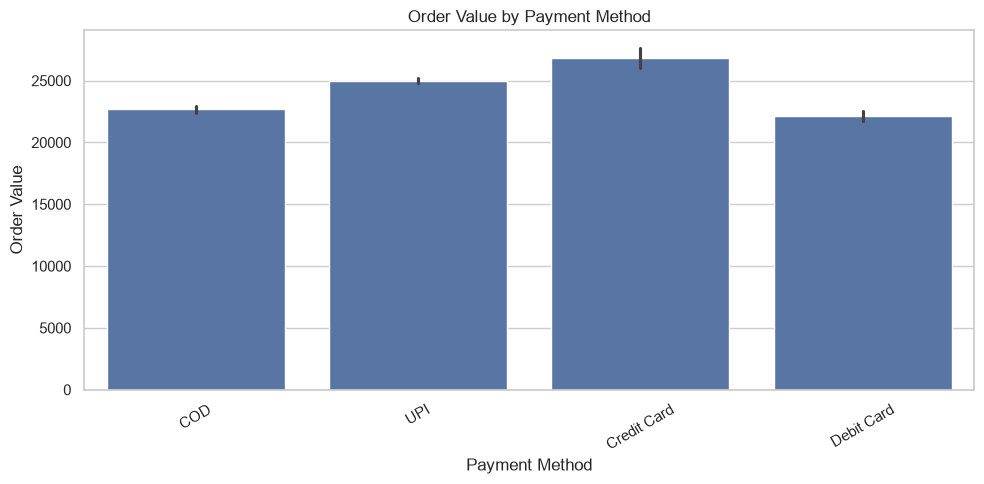

In [68]:

plt.figure(figsize=(10, 5))

sns.barplot(data=sales, x="Payment_Mode", y="Order_Value")

plt.title("Order Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Order Value")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


: Are most order amounts small, medium, or large?

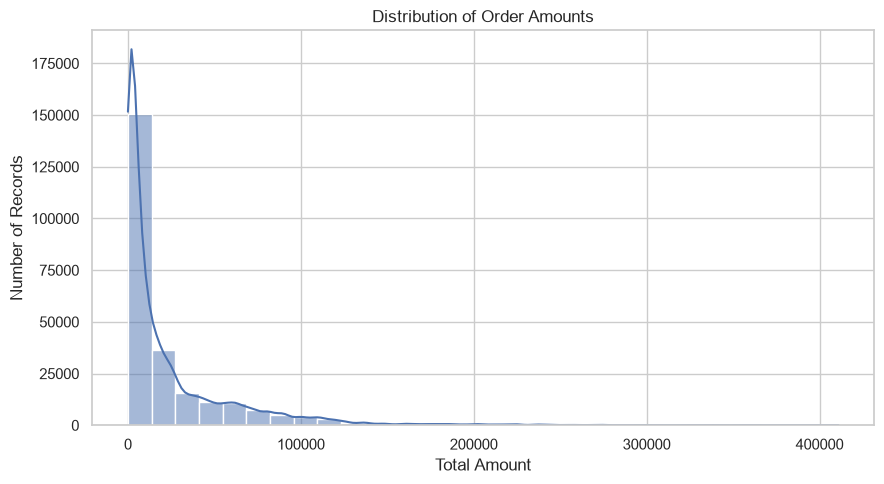

In [69]:

plt.figure(figsize=(9, 5))

sns.histplot(data=sales, x="Total_Amount", bins=30, kde=True)

plt.title("Distribution of Order Amounts")
plt.xlabel("Total Amount")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


Which categories have the highest average recorded rating

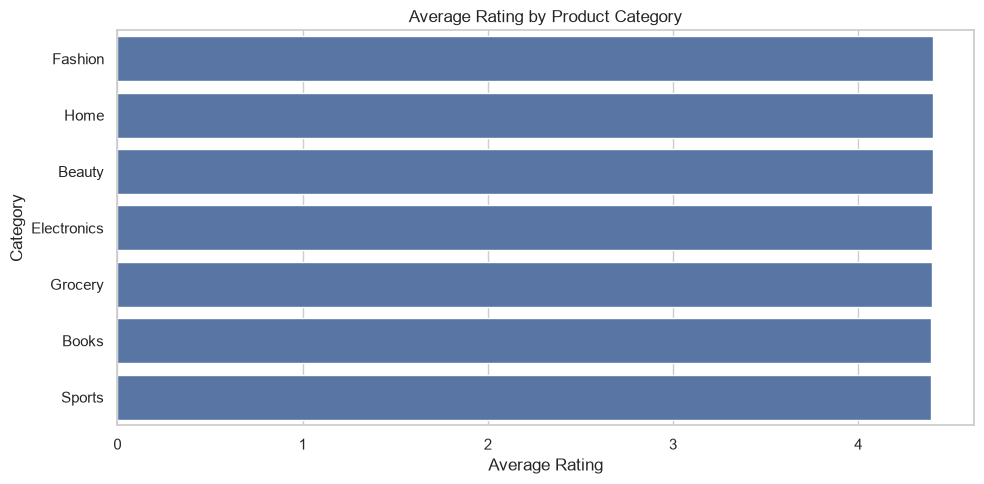

In [70]:

rating_by_category = (
    sales_product.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=rating_by_category.values,
    y=rating_by_category.index
)

plt.title("Average Rating by Product Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


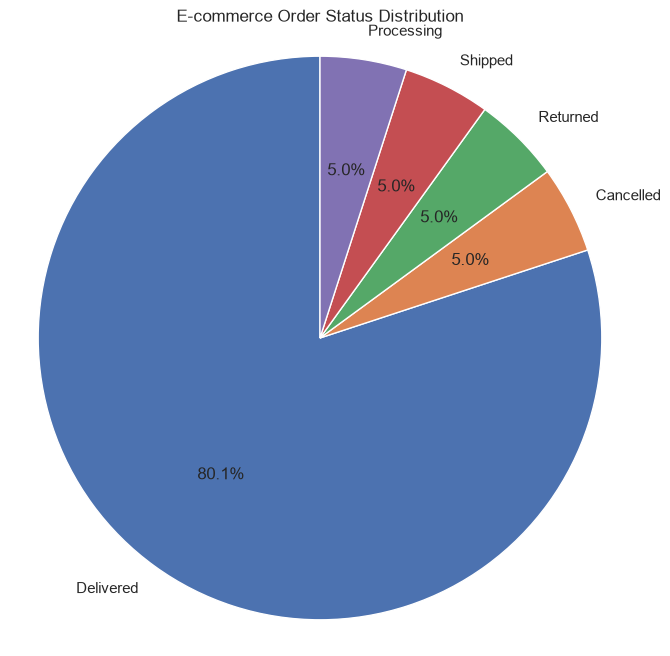

In [71]:
# Count orders by status
status_counts = sales["Order_Status"].value_counts()

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    shadow=False
)

plt.title("E-commerce Order Status Distribution")
plt.axis("equal")
plt.show()